In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

# Point Python to your project's src directory
sys.path.append(str(Path("../src").resolve()))

In [3]:
import chess
import pandas as pd
import torch
from torch import nn

In [4]:
planes = torch.zeros((12, 8, 8), dtype=torch.float32)
planes.shape

torch.Size([12, 8, 8])

In [5]:
planes.flatten().shape

torch.Size([768])

In [6]:
print(planes.shape)
print(planes.ndim)
print(planes.numel())

torch.Size([12, 8, 8])
3
768


In [7]:
planes[0, 6, 4] = 1

print(planes[0])

tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])


In [8]:
torch.zeros(5)

tensor([0., 0., 0., 0., 0.])

In [9]:
def encode_board_example(board: chess.Board) -> torch.Tensor:
    planes = torch.zeros((12, 8, 8), dtype=torch.float32)

    for square, piece in board.piece_map().items():
        plane_index = PIECE_TO_PLANE[(piece.color, piece.piece_type)]

        row = 7 - chess.square_rank(square)
        col = chess.square_file(square)

        planes[plane_index, row, col] = 1.0

    flat = planes.flatten()
    # [white_to_move, white_K, white_Q, black_K, black_Q]
    features = torch.empty(5, dtype=torch.float32)
    features[0] = float(board.turn == chess.WHITE)
    features[1] = float(board.has_kingside_castling_rights(chess.WHITE))
    features[2] = float(board.has_queenside_castling_rights(chess.WHITE))
    features[3] = float(board.has_kingside_castling_rights(chess.BLACK))
    features[4] = float(board.has_queenside_castling_rights(chess.BLACK))

    result = torch.cat((flat, features))
    return result

In [10]:
PIECE_TO_PLANE = {
    (chess.WHITE, chess.PAWN): 0,
    (chess.WHITE, chess.KNIGHT): 1,
    (chess.WHITE, chess.BISHOP): 2,
    (chess.WHITE, chess.ROOK): 3,
    (chess.WHITE, chess.QUEEN): 4,
    (chess.WHITE, chess.KING): 5,
    (chess.BLACK, chess.PAWN): 6,
    (chess.BLACK, chess.KNIGHT): 7,
    (chess.BLACK, chess.BISHOP): 8,
    (chess.BLACK, chess.ROOK): 9,
    (chess.BLACK, chess.QUEEN): 10,
    (chess.BLACK, chess.KING): 11,
}

In [11]:
from neurachess.neural.encoding import encode_board

board = chess.Board()
x = encode_board(board)

assert torch.equal(x, encode_board_example(board))
print("Shape:", x.shape)
print("Pieces:", x[:768].sum().item())
print("Global features:", x[-5:])

Shape: torch.Size([773])
Pieces: 32.0
Global features: tensor([1., 1., 1., 1., 1.])


In [12]:
board.push_uci("e2e4")
x = encode_board(board)

print(x.shape)
print(x[-5:])

torch.Size([773])
tensor([0., 1., 1., 1., 1.])


In [13]:
df = pd.read_parquet("../data/chess_positions.parquet")
df.head()

,fen,cp,raw_cp,depth,eval_bucket,game_phase
0,rnb1kbnr/pp2pppp/3q4/8/8/2pQ4/PP2PPPP/R1B1KBNR...,-507,-507,22,strong_black,opening
1,rn1qkb1r/5ppp/b3pn2/2pp4/3PP3/2N3P1/PP3PBP/R1B...,-262,-262,21,moderate_black,opening
2,rnb1kb1r/ppppnp1p/6p1/4p1B1/4P3/2NP4/PqP2PPP/R...,32,32,20,equal,opening
3,r1bqk1nr/ppp2pp1/1bn1p2p/3pP3/1P1P4/P1N5/2P1NP...,161,161,21,moderate_white,opening
4,r1bq1rk1/ppp2ppp/3b4/8/2P5/5N1P/PP2PPP1/RNBQKB...,581,581,30,strong_white,opening


In [14]:
from neurachess.neural.dataset import ChessDataset

dataset = ChessDataset("../data/encoded")

print("Dataset size:", len(dataset))

x, y = dataset[0]

print("Input shape:", x.shape)
print("Target shape:", y.shape)
print("Target evaluation:", y)
print("*")

Dataset size: 1000000
Input shape: torch.Size([773])
Target shape: torch.Size([1])
Target evaluation: tensor([-5.0700])
*


In [15]:
import torch
from torch.utils.data import DataLoader, random_split

from neurachess.neural.dataset import ChessDataset

dataset = ChessDataset("../data/encoded")

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [0.8, 0.1, 0.1],
    generator=torch.Generator().manual_seed(42),
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False,
)

In [16]:
from neurachess.neural.model import ChessEvaluator

model = ChessEvaluator(hidden_sizes=(256, 128))

loss_fn = nn.MSELoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=0.01,
)

In [17]:
model.train()

total_loss = 0.0

for X_batch, y_batch in train_loader:
    optimizer.zero_grad()

    predictions = model(X_batch)

    loss = loss_fn(predictions, y_batch)

    loss.backward()
    optimizer.step()

    total_loss += loss.item() * X_batch.size(0)

train_loss = total_loss / len(train_loader.dataset)

print(f"Training MSE: {train_loss:.4f}")

Training MSE: 15.7248


In [18]:
model.eval()

total_val_loss = 0.0

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        predictions = model(X_batch)

        loss = loss_fn(predictions, y_batch)

        total_val_loss += loss.item() * X_batch.size(0)

val_loss = total_val_loss / len(val_loader.dataset)

print(f"Validation MSE: {val_loss:.4f}")

Validation MSE: 13.7449


In [38]:
import copy
from pathlib import Path

import torch

from neurachess.neural.model import ChessEvaluator
from neurachess.neural.train import train_one_epoch, validate

torch.manual_seed(42)

HIDDEN_SIZES = (512, 256, 128)
DROPOUT = 0.1
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.01

EPOCHS = 40
PATIENCE = 4

model = ChessEvaluator(
    input_size=773,
    hidden_sizes=HIDDEN_SIZES,
    activation=torch.nn.GELU,
    dropout=DROPOUT,
    use_layer_norm=True,
)

loss_fn = torch.nn.HuberLoss(delta=1.0)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

checkpoint_dir = Path("../checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_mae_cp": [],
    "val_mae_cp": [],
}

best_val_loss = float("inf")
best_val_mae = float("inf")
best_state = None
best_epoch = 0
no_improvement = 0

for epoch in range(EPOCHS):
    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        loss_fn,
        track_gradients=False,
    )

    val_metrics = validate(
        model,
        val_loader,
        loss_fn,
    )

    history["train_loss"].append(train_metrics["mse"])
    history["val_loss"].append(val_metrics["mse"])
    history["train_mae_cp"].append(train_metrics["mae_cp"])
    history["val_mae_cp"].append(val_metrics["mae_cp"])

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_metrics['mse']:.4f} | "
        f"Val Loss: {val_metrics['mse']:.4f} | "
        f"Val MAE: {val_metrics['mae_cp']:.2f} cp"
    )

    if val_metrics["mae_cp"] < best_val_mae:
        best_val_mae = val_metrics["mae_cp"]
        best_val_loss = val_metrics["mse"]
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model.state_dict())
        no_improvement = 0
    else:
        no_improvement += 1

    if no_improvement >= PATIENCE:
        print("Early stopping")
        break

model.load_state_dict(best_state)

print(f"\nBest epoch: {best_epoch}")
print(f"Best validation MAE: {best_val_mae:.2f} cp")


# Find the best previously saved version
previous_best_mae = float("inf")
next_version = 1

for path in sorted(checkpoint_dir.glob("model_v*.pt")):
    checkpoint = torch.load(path, weights_only=True)

    previous_best_mae = min(previous_best_mae, checkpoint["val_mae_cp"])

    version = int(path.stem.split("_v")[1])
    next_version = max(next_version, version + 1)


# Save only if this training run beats previous versions
if best_val_mae < previous_best_mae:
    new_path = checkpoint_dir / f"model_v{next_version:03d}.pt"

    torch.save(
        {
            "epoch": best_epoch,
            "model_state_dict": best_state,
            "val_mae_cp": best_val_mae,
            "val_loss": best_val_loss,
            "hidden_sizes": HIDDEN_SIZES,
            "input_size": 773,
            "dropout": DROPOUT,
            "activation": "GELU",
            "use_layer_norm": True,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "loss_function": "HuberLoss",
        },
        new_path,
    )

    print(f"New best model saved: {new_path.name}")

else:
    print("No improvement over previous models. Checkpoint not saved.")

Epoch 01/40 | Train Loss: 2.2496 | Val Loss: 1.9168 | Val MAE: 234.20 cp
Epoch 02/40 | Train Loss: 1.8475 | Val Loss: 1.8062 | Val MAE: 222.87 cp
Epoch 03/40 | Train Loss: 1.6998 | Val Loss: 1.7283 | Val MAE: 214.44 cp
Epoch 04/40 | Train Loss: 1.6056 | Val Loss: 1.6830 | Val MAE: 209.78 cp
Epoch 05/40 | Train Loss: 1.5342 | Val Loss: 1.6459 | Val MAE: 205.75 cp
Epoch 06/40 | Train Loss: 1.4804 | Val Loss: 1.6366 | Val MAE: 204.68 cp
Epoch 07/40 | Train Loss: 1.4308 | Val Loss: 1.5982 | Val MAE: 200.60 cp
Epoch 08/40 | Train Loss: 1.3911 | Val Loss: 1.5843 | Val MAE: 199.22 cp
Epoch 09/40 | Train Loss: 1.3603 | Val Loss: 1.5674 | Val MAE: 197.24 cp
Epoch 10/40 | Train Loss: 1.3312 | Val Loss: 1.5714 | Val MAE: 197.79 cp
Epoch 11/40 | Train Loss: 1.3054 | Val Loss: 1.5559 | Val MAE: 196.01 cp
Epoch 12/40 | Train Loss: 1.2831 | Val Loss: 1.5433 | Val MAE: 194.71 cp
Epoch 13/40 | Train Loss: 1.2645 | Val Loss: 1.5431 | Val MAE: 194.62 cp
Epoch 14/40 | Train Loss: 1.2422 | Val Loss: 1.5316

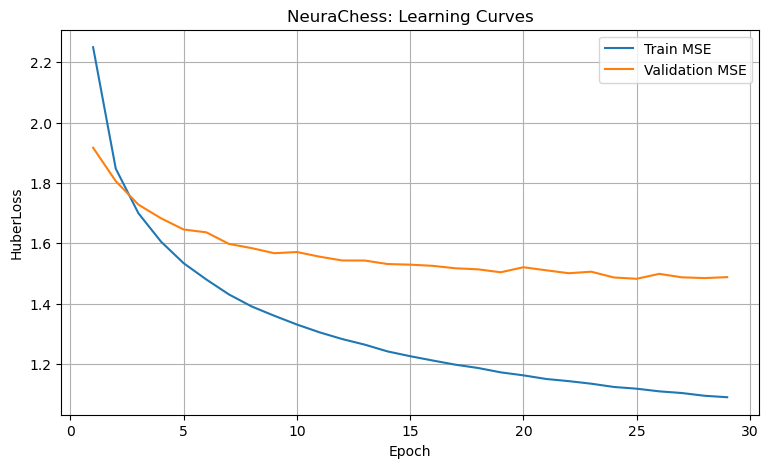

In [40]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(9, 5))

plt.plot(epochs, history["train_loss"], label="Train MSE")
plt.plot(epochs, history["val_loss"], label="Validation MSE")

plt.xlabel("Epoch")
plt.ylabel("HuberLoss")
plt.title("NeuraChess: Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

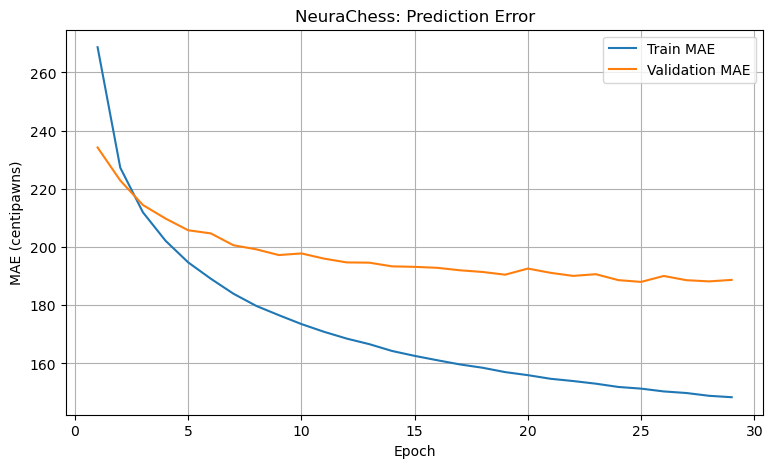

In [41]:
plt.figure(figsize=(9, 5))

plt.plot(epochs, history["train_mae_cp"], label="Train MAE")
plt.plot(epochs, history["val_mae_cp"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE (centipawns)")
plt.title("NeuraChess: Prediction Error")
plt.legend()
plt.grid(True)
plt.show()

In [44]:
checkpoint = torch.load(
    "../checkpoints/model_v001.pt",
    weights_only=True,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

ChessEvaluator(
  (network): Sequential(
    (0): Linear(in_features=773, out_features=512, bias=True)
    (1): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (10): GELU(approximate='none')
    (11): Dropout(p=0.1, inplace=False)
    (12): Linear(in_features=128, out_features=1, bias=True)
  )
)

In [45]:
import numpy as np

predictions = []
actuals = []

with torch.no_grad():
    for X, y in val_loader:
        output = model(X)

        predictions.extend(output.flatten().tolist())
        actuals.extend(y.flatten().tolist())

predictions = np.array(predictions)
actuals = np.array(actuals)

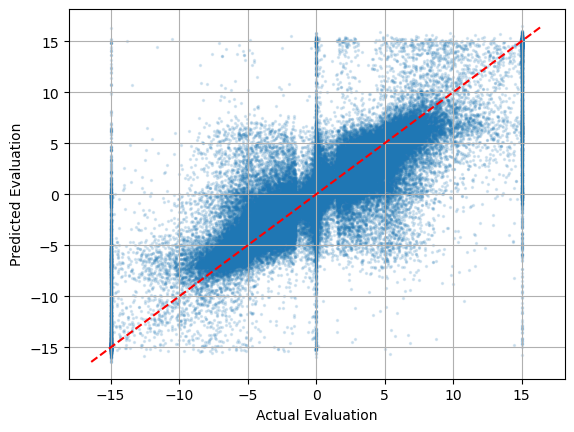

In [46]:
minimum = min(actuals.min(), predictions.min())
maximum = max(actuals.max(), predictions.max())

plt.scatter(actuals, predictions, s=2, alpha=0.15)

plt.plot([minimum, maximum], [minimum, maximum], "r--")

plt.xlabel("Actual Evaluation")
plt.ylabel("Predicted Evaluation")
plt.grid()
plt.show()

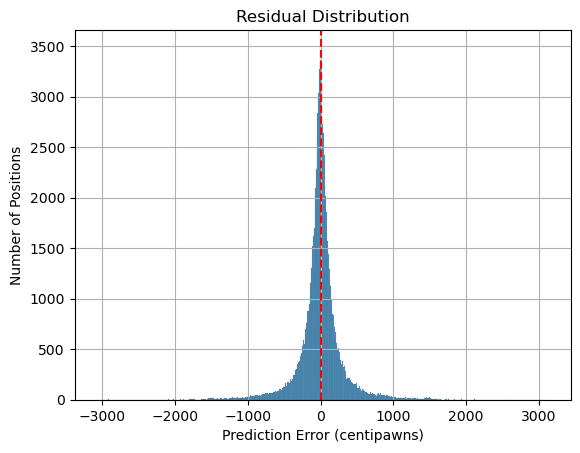

In [47]:
import seaborn as sns

errors = (predictions - actuals) * 100

sns.histplot(errors)
plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Prediction Error (centipawns)")
plt.ylabel("Number of Positions")
plt.title("Residual Distribution")
plt.grid()
plt.show()

In [37]:
print("At -15:", (actuals == -15).sum())
print("At 0:", (actuals == 0).sum())
print("At +15:", (actuals == 15).sum())

At -15: 2215
At 0: 6935
At +15: 2976
